# Chapter 4 — Introduction to Neural Learning: Gradient Descent

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 4 (compare + learn), explain every theory, and reproduce the code.

---

## 1. Chapter Summary

Chapter 3 gave us **Predict**. Chapter 4 adds **Compare** and a first look at **Learn**:

1. **Compare** — measure *how much we missed by*. The book uses **mean squared error (MSE)** per example: `error = (pred - goal)²`.
2. **Why squared?** Always positive (no cancelling), and large misses are punished far more than small ones.
3. **Learn** — change the weight so the error becomes smaller. It is "just" a search for the weight value that minimises the error.
4. **Hot and cold learning** — the simplest (and crude) learning algorithm: try `weight + step` and `weight − step`, keep whichever gives the lower error. It works but is slow and needs a hand-tuned step size.
5. **Gradient descent** — a much better idea: compute *the direction and the amount* to change the weight directly from the error. The key quantity is `pred − goal` multiplied by the input. The error surface is a bowl ("valley"); gradient descent rolls down it.
6. **Derivative intuition** — *"How much does one thing change when I wiggle another?"* The slope of the error w.r.t. the weight tells us which way to move.

---

## 2. Theory Deep-Dive

### 2.1 Error measures
| Measure | Formula | Notes |
|---|---|---|
| Absolute error | $\lvert \hat y - y\rvert$ | gradient has constant size: slow to settle |
| **Squared error** | $(\hat y - y)^2$ | smooth bowl shape; big errors → big corrections; small errors → tiny ones |
| Mean squared error | $\frac1N\sum(\hat y_i-y_i)^2$ | average over a dataset |

With $\hat y = x\,w$ the error is a function of the weight alone:
$$E(w) = (x w - y)^2$$
That is a **parabola** in $w$ with a single minimum. *Learning = finding the bottom of this parabola.*

### 2.2 Hot and cold learning
```
try w + step  → error_up
try w - step  → error_down
move in whichever direction gave the lower error
```
**Characteristics / problems**
* It's *very inefficient*: 2 extra predictions per update.
* Step size is arbitrary: too large → it never settles exactly (jitters around the minimum); too small → very slow.
* It tells us the *direction* but not *how far* to go.

### 2.3 Gradient descent — direction **and** amount
Differentiate the error with respect to the weight:

$$\frac{\partial E}{\partial w} = 2\,(xw - y)\,x$$

* The **sign** says which way the error grows.
* The **magnitude** says how steep it is → the further we are from the goal, the bigger the step. This *automatically* shrinks the step as we approach the bottom, so there is no jitter.

Update rule (the factor 2 is absorbed into the learning rate later):
$$w \leftarrow w - (\hat y - y)\cdot x$$

Three parts of `direction_and_amount = (pred - goal) * input`:
1. **Pure error** `pred − goal` — scale and sign of the miss.
2. **Scaling** by `input` — the input's size controls how much the weight mattered (a zero input → no change; larger input → larger effect).
3. **Negative sign** (`−=`) — move *against* the slope.

### 2.4 Derivative intuition
A derivative is the *sensitivity* of one quantity to another: "if I increase the weight by a tiny bit, how much (and in which direction) does the error change?" Positive slope → decrease the weight. Negative slope → increase it.

---

## 3. Code Reproduction

### 3.1 Compare: measuring error

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("folder-picture", exist_ok=True)

knob_weight = 0.5
input_ = 0.5
goal_pred = 0.8

pred = input_ * knob_weight
error = (pred - goal_pred) ** 2
print("prediction:", pred, "  squared error:", error)

prediction: 0.25   squared error: 0.30250000000000005


### 3.2 Hot and cold learning

In [2]:
weight = 0.5
input_ = 0.5
goal_prediction = 0.8
step_amount = 0.001

hc_errors = []
for iteration in range(1101):
    prediction = input_ * weight
    error = (prediction - goal_prediction) ** 2
    hc_errors.append(error)
    if iteration % 200 == 0:
        print(f"iter {iteration:4d}  Error: {error:.8f}  Prediction: {prediction:.6f}")

    up_prediction = input_ * (weight + step_amount)
    up_error = (goal_prediction - up_prediction) ** 2

    down_prediction = input_ * (weight - step_amount)
    down_error = (goal_prediction - down_prediction) ** 2

    if down_error < up_error:
        weight = weight - step_amount
    if down_error > up_error:
        weight = weight + step_amount

iter    0  Error: 0.30250000  Prediction: 0.250000
iter  200  Error: 0.20250000  Prediction: 0.350000
iter  400  Error: 0.12250000  Prediction: 0.450000
iter  600  Error: 0.06250000  Prediction: 0.550000
iter  800  Error: 0.02250000  Prediction: 0.650000
iter 1000  Error: 0.00250000  Prediction: 0.750000


Hot and cold *does* converge, but it needed over a thousand iterations (and two extra predictions per iteration) for a problem with one weight. Next: gradient descent.

### 3.3 Gradient descent (one weight)

In [3]:
weight = 0.5
goal_pred = 0.8
input_ = 0.5

gd_errors, gd_weights = [], []
for iteration in range(20):
    pred = input_ * weight
    error = (pred - goal_pred) ** 2
    delta = pred - goal_pred                 # pure error (signed)
    weight_delta = delta * input_            # direction and amount
    weight = weight - weight_delta
    gd_errors.append(error); gd_weights.append(weight)
    if iteration < 4 or iteration == 19:
        print(f"iter {iteration:2d}  Error: {error:.8f}  Prediction: {pred:.6f}")

iter  0  Error: 0.30250000  Prediction: 0.250000
iter  1  Error: 0.17015625  Prediction: 0.387500
iter  2  Error: 0.09571289  Prediction: 0.490625
iter  3  Error: 0.05383850  Prediction: 0.567969
iter 19  Error: 0.00000541  Prediction: 0.797674


### 3.4 Visualising the error bowl and the descent

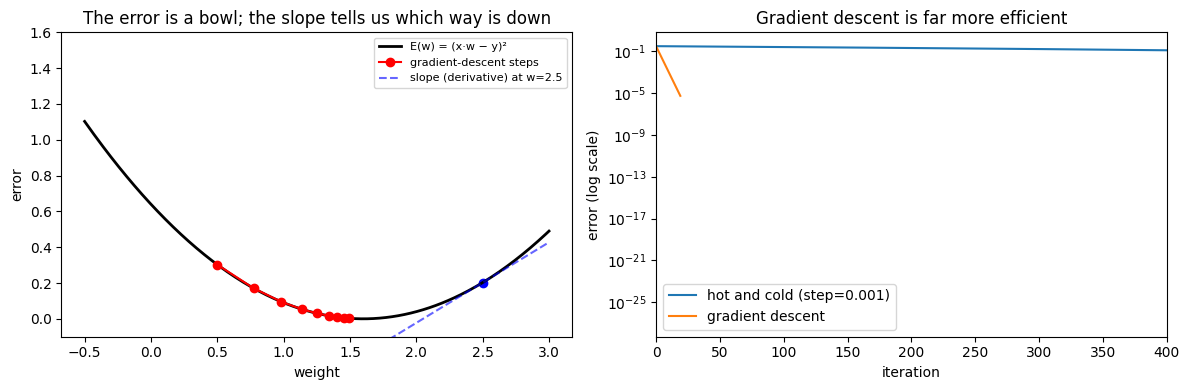

In [4]:
ws = np.linspace(-0.5, 3.0, 300)
E = (input_ * ws - goal_pred) ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# (a) error surface with the gradient-descent path
ax[0].plot(ws, E, "k", lw=2, label="E(w) = (x·w − y)²")
path_w = [0.5] + gd_weights[:8]
path_e = [(input_ * w - goal_pred) ** 2 for w in path_w]
ax[0].plot(path_w, path_e, "ro-", label="gradient-descent steps")
# tangent line at the start
w0 = 2.5; slope = 2 * (input_ * w0 - goal_pred) * input_
ax[0].plot(ws, (input_ * w0 - goal_pred) ** 2 + slope * (ws - w0), "b--", alpha=.6, label="slope (derivative) at w=2.5")
ax[0].scatter([w0], [(input_ * w0 - goal_pred) ** 2], c="b")
ax[0].set_ylim(-0.1, 1.6); ax[0].set_xlabel("weight"); ax[0].set_ylabel("error")
ax[0].set_title("The error is a bowl; the slope tells us which way is down"); ax[0].legend(fontsize=8)

# (b) hot&cold vs gradient descent
ax[1].plot(hc_errors, label="hot and cold (step=0.001)")
ax[1].plot(gd_errors, label="gradient descent")
ax[1].set_yscale("log"); ax[1].set_xlim(0, 400)
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("error (log scale)")
ax[1].set_title("Gradient descent is far more efficient"); ax[1].legend()
plt.tight_layout()
plt.savefig("folder-picture/ch04_error_bowl_and_descent.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.5 Pure error, scaling and the sign — a worked example with inspection

The book's "breaking gradient descent apart" example prints the three ingredients of the update.

In [5]:
weight, goal_pred, input_ = 0.0, 0.8, 1.1

for iteration in range(4):
    print("-----\nWeight:", round(weight, 4))
    pred = input_ * weight
    error = (pred - goal_pred) ** 2
    delta = pred - goal_pred
    weight_delta = input_ * delta
    weight -= weight_delta
    print(f"Error:{error:.4f}  Prediction:{pred:.4f}")
    print(f"Delta:{delta:.4f}  Weight Delta:{weight_delta:.4f}")

-----
Weight: 0.0
Error:0.6400  Prediction:0.0000
Delta:-0.8000  Weight Delta:-0.8800
-----
Weight: 0.88
Error:0.0282  Prediction:0.9680
Delta:0.1680  Weight Delta:0.1848
-----
Weight: 0.6952
Error:0.0012  Prediction:0.7647
Delta:-0.0353  Weight Delta:-0.0388
-----
Weight: 0.734
Error:0.0001  Prediction:0.8074
Delta:0.0074  Weight Delta:0.0081


---

## 4. Key Takeaways

* **Error** = squared difference between prediction and truth → a smooth bowl in weight-space.
* **Hot & cold** learning is the "try both directions" baseline: simple, slow, jittery.
* **Gradient descent** uses the **derivative** of the error to get both *direction* and *amount* in one computation: `weight -= (pred − goal) * input`.
* The step shrinks automatically as the error shrinks — convergence is smooth.

➡️ **Next:** Chapter 5 — gradient descent in full (learning rate `alpha`, divergence, many inputs/outputs).